In [1]:
import pandas as pd
import numpy as np 
from sklearn.neighbors import NearestNeighbors
from scipy import spatial
import spatialdata_preprocessing


In [55]:
#data = pd.read_csv('/Users/ethan/Downloads/puck_data/2020-02-02_Puck_200102_24_RCTD_state0all.csv')
data = pd.read_pickle('/Users/ethan/Downloads/puck_data/Puck_200102_24_RCTD_downsampled.pkl')
data.dropna(inplace=True)
#data.set_index(data.columns[0], inplace=True)
data.head()

,x,y,anchor,B cells,Endothelial,Fibroblasts,Granulocytes,Macrophages,Monocytes,NK cells,T cells,enterocytes,enteroendocrine,epithelial,goblet
CCCCTAACGGTAAC,1912.6,4180.2,True,0.000121,0.000121,0.000121,0.000121,0.157820,0.000121,0.325920,0.000121,0.151301,0.000121,0.000121,0.363988
TCGCGACATTGCCC,4139.7,1633.5,True,0.000204,0.000204,0.000204,0.000204,0.486860,0.000204,0.000204,0.000204,0.511096,0.000204,0.000204,0.000204
TCACCATAGGTTCT,3483.8,3858.0,True,0.053847,0.000040,0.000040,0.000040,0.000040,0.000040,0.000040,0.350618,0.050434,0.000040,0.000040,0.544779
TACACAGACTTCGA,4420.9,3218.0,True,0.121705,0.000108,0.000112,0.000108,0.000108,0.000108,0.000108,0.000108,0.000108,0.000108,0.877211,0.000108
CGGTTTAATCAGTT,3563.1,3615.2,True,0.023073,0.000011,0.000011,0.000011,0.000011,0.000011,0.000011,0.838873,0.000011,0.000046,0.137921,0.000011


In [4]:
loc_df = pd.read_csv('/Users/ethan/Downloads/puck_data/2020-02-02_Puck_200102_24_locs.csv')
loc_df.columns = ['idx','barcode', 'x', 'y']
loc_df.drop(loc_df.columns[0], axis= 1, inplace = True)
loc_df.set_index("barcode", inplace=True)


In [54]:
merged_df = loc_df.merge(data, left_index=True, right_index=True)
merged_df.head()

,x,y,B cells,Endothelial,Fibroblasts,Granulocytes,Macrophages,Monocytes,NK cells,T cells,enterocytes,enteroendocrine,epithelial,goblet
TAACCTTCGACCCA,3880.1,5392.3,0.053057,0.024704,0.168295,0.000050,0.073836,0.000050,0.006873,0.000050,0.001095,0.005243,0.385631,0.281115
ACACCAGCGTGTCG,4594.6,3566.6,0.059087,0.019382,0.197930,0.000047,0.120426,0.000047,0.000047,0.009178,0.002591,0.000047,0.381304,0.209915
ACGGGACACTACGG,1078.4,3252.8,0.036678,0.025337,0.112141,0.000070,0.103199,0.000070,0.014061,0.000070,0.028874,0.000070,0.336815,0.342613
AACAGTCCACATCT,1919.8,4949.9,0.000118,0.037403,0.076611,0.000118,0.049522,0.005542,0.000118,0.009164,0.000126,0.022055,0.370292,0.428933
AACTTGTTGCTATT,3324.4,2340.0,0.000038,0.000038,0.005828,0.012117,0.000038,0.000038,0.008912,0.000038,0.073685,0.005681,0.298803,0.594783


In [55]:
merged_df = merged_df.sample(n=30000)

In [56]:
points = spatialdata_preprocessing.make_points_arr(data, 'x', 'y')

In [57]:
distance_matrix = spatial.distance.cdist(points, points)

In [58]:
markers = spatialdata_preprocessing.make_marker_arr(data, 3)

In [59]:
featurized_data = spatialdata_preprocessing.calculate_weighted_markers(distance_matrix, markers,                                                                          sigma=250)

Featurizing data...
100%|██████████| 19883/19883 [00:33<00:00, 585.97it/s]


In [37]:
sigma = 250
weights = np.exp(-(np.power(distance_matrix, 2)/sigma**2))
weights = np.nan_to_num(weights)

In [54]:
data.iloc[406, :]

x                  2783.9
y                  873.93
anchor               True
B cells               NaN
Endothelial           NaN
Fibroblasts           NaN
Granulocytes          NaN
Macrophages           NaN
Monocytes             NaN
NK cells              NaN
T cells               NaN
enterocytes           NaN
enteroendocrine       NaN
epithelial            NaN
goblet                NaN
Name: AAATCTTACAGTAA, dtype: object

In [44]:
featurized_data = np.empty(markers.shape)
for i in trange(0, distance_matrix.shape[0]):
        featurized_data[i, :] = np.mean((weights[i, :] * markers.T).T, axis=0)

100%|██████████| 20000/20000 [00:34<00:00, 572.02it/s]


In [49]:
(weights[i, :] * markers.T).T

array([[8.22743075e-83, 8.22743075e-83, 8.22743075e-83, ...,
        8.22743075e-83, 8.22743075e-83, 2.46545822e-79],
       [9.66766359e-22, 9.66766359e-22, 9.66766359e-22, ...,
        9.66766359e-22, 9.66766359e-22, 9.66766359e-22],
       [1.12937706e-65, 8.44061698e-69, 8.44061698e-69, ...,
        8.44061698e-69, 8.44061698e-69, 1.14320617e-64],
       ...,
       [5.25870661e-21, 3.76552267e-24, 4.76221420e-20, ...,
        3.76552267e-24, 9.04850077e-21, 2.63816678e-20],
       [1.26749550e-71, 1.16850431e-71, 1.97778283e-71, ...,
        1.29811133e-71, 6.96408156e-71, 2.34517283e-71],
       [4.33349609e-02, 4.66108322e-05, 1.80206299e-02, ...,
        1.24053955e-02, 1.59740448e-04, 3.52539062e-01]])

In [39]:
import slda
import image_processing
import torch
from tqdm import trange

In [60]:
vocab_size = 100 #best = [75,5,20,50]
n_topics = 5
sigma = 250
n_docs = 200

alpha = torch.ones((n_topics,))/n_topics
beta = torch.ones(vocab_size)/vocab_size

all_words = featurized_data
kmeans, assignments = spatialdata_preprocessing.cluster_descriptors(all_words, vocab_size)

In [61]:
ids = np.zeros((points.shape[0],1))
c = np.concatenate([ids, points], axis=1)

In [62]:
input_arr = slda.build_input_word_array(assignments, c)
n_imgs = 1

In [63]:
z, docs, n_dk, n_kw, n_d, n_k = slda.initialize_model(input_arr, n_imgs, n_docs, n_topics, vocab_size)

In [64]:
document_locs, docs_in_img = slda.initialize_documents_spatialdata(c, n_docs, n_imgs)

In [65]:
pi_hat, phi_hat, n_dk, n_kw, n_k, n_d, docs, z = slda.train_model(input_arr, document_locs, docs_in_img, n_imgs, n_docs, n_topics, vocab_size, z, docs, n_dk, n_kw, n_d, n_k, alpha, beta, sigma, n_epochs=10)

  0%|          | 0/19883 [00:00<?, ?it/s]/Users/ethan/Dropbox (MIT)/Lab/lda_implementations/slda/code/slda.py:205: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)
100%|██████████| 19883/19883 [00:15<00:00, 1307.54it/s]
9 tensor(29.5512)


In [31]:
from tqdm import trange

In [74]:
best_topics = torch.zeros((phi_hat.shape[1], pi_hat.shape[0], phi_hat.shape[0]))

for w in range(phi_hat.shape[1]):
    for d in range(pi_hat.shape[0]):
        best_topics[w][d] = pi_hat[d]*phi_hat[:, w]

best_topic = torch.zeros((len(c),))
x_i_new, y_i_new, all_gx, all_gy = slda.make_vectorizable_vars(document_locs, input_arr, n_docs)

topic_probs = torch.zeros((best_topic.shape[0], n_topics))
for i in trange(0, best_topic.shape[0]):
    g = int(c[i, 0])
    x = c[i, 1]
    y = c[i, 2]
    word = assignments[i]
    start = g * n_docs
    end = (g+1) * n_docs
    p = best_topics[word, start:end, :].T @ torch.exp(-((x-document_locs[start:end, 1])**2 + (y-document_locs[start:end, 2])**2)/sigma**2)
    best_topic[i] = p.argmax()
    topic_probs[i, :] = p

100%|██████████| 19883/19883 [00:02<00:00, 8368.05it/s]


In [67]:
best_topic

tensor([3., 2., 2.,  ..., 3., 0., 1.])

In [68]:
val, count = torch.unique(best_topic, return_counts=True)

In [76]:
topic_probs[-1, :]

tensor([3.0954e-08, 1.0372e-02, 7.8292e-09, 2.1843e-09, 8.6619e-09])

In [69]:
colors = ['#15b01a','#0343df', '#ff81c0', '#f97306', '#653700']
color_dict = dict(zip(val.tolist(), colors))
color_assigments = [color_dict[j] for j in best_topic.tolist()]



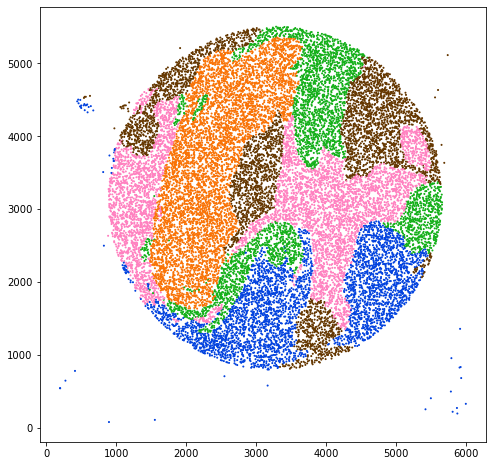

In [70]:
import matplotlib.pyplot as plt 
fig, ax = plt.subplots(1,1, figsize=(8,8))
ax.scatter(x=points[:, 0], y = points[:, 1], c=color_assigments, s = 1)

In [71]:
best_topic

tensor([3., 2., 2.,  ..., 3., 0., 1.])

In [78]:
topic_probs.numpy().shape

(19883, 5)

In [91]:
topic_df = pd.DataFrame(np.concatenate([points, topic_probs.numpy()], axis=1), index=data.index, columns = ['x', 'y', 'Topic0', 'Topic1', 'Topic2', 'Topic3', 'Topic4'])

topic_df.to_csv('./Puck_200102_24_RCTD_downsampled_topicweights_topics=5_SLDApaper.pkl')

In [88]:
points

array([[1912.6 , 4180.2 ],
       [4139.7 , 1633.5 ],
       [3483.8 , 3858.  ],
       ...,
       [1681.2 , 2202.5 ],
       [4183.1 , 3741.6 ],
       [2727.7 ,  926.73]])

In [93]:
calico_df = pd.read_pickle('~/Downloads/puck_data/Puck_200102_24_RCTD_downsampled_topicweights_penalty=250_topics=5_anchor=all.pkl')

In [94]:
calico_df.shape

(20000, 5)

In [99]:
orig = list(calico_df.index)
new_idx = [i[1] for i in orig]

In [104]:
calico_df.set_index(np.array(new_idx), inplace=True)

In [118]:
topic_comparison = topic_df.merge(calico_df, left_index=True, right_index=True)

In [122]:
topic_comparison.to_csv('./Puck_200102_24_RCTD_downsampled_topicweights_topics=5_calicoSLDAcomparison.csv')

In [123]:
topic_comparison

,x,y,Topic0,Topic1,Topic2,Topic3,Topic4,Topic-0,Topic-1,Topic-2,Topic-3,Topic-4
CCCCTAACGGTAAC,1912.6,4180.20,7.853877e-04,5.379745e-08,5.641836e-03,1.390217e-02,9.373148e-07,0.941755,0.014303,0.014526,0.014573,0.014843
TCGCGACATTGCCC,4139.7,1633.50,3.529675e-08,2.115410e-06,9.317448e-03,2.487156e-08,4.097396e-03,0.574756,0.028692,0.338072,0.029450,0.029031
TCACCATAGGTTCT,3483.8,3858.00,1.221171e-06,2.269344e-08,1.416619e-01,8.350045e-08,5.138367e-04,0.644956,0.028733,0.029047,0.267681,0.029583
TACACAGACTTCGA,4420.9,3218.00,8.936113e-08,1.262424e-07,7.086293e-02,1.529587e-08,1.240684e-02,0.020916,0.020033,0.020485,0.917494,0.021072
CGGTTTAATCAGTT,3563.1,3615.20,1.421071e-06,3.706513e-08,2.436545e-01,2.947073e-08,1.603162e-04,0.050841,0.050046,0.351956,0.050214,0.496943
...,...,...,...,...,...,...,...,...,...,...,...,...
AAAGGATGGCATGC,4585.1,1423.10,2.727903e-08,8.058813e-02,4.322095e-07,1.922757e-08,3.148121e-07,0.937773,0.015487,0.015592,0.015514,0.015634
GACACAACGTCGGA,1539.6,4304.30,6.472862e-07,1.018199e-07,1.846094e-03,3.056599e-07,3.987451e-02,0.014031,0.013440,0.013647,0.013752,0.945130
TACGCAGATCGATA,1681.2,2202.50,6.489277e-04,8.777183e-08,2.501017e-07,2.215264e-02,1.325198e-08,0.017355,0.508306,0.017061,0.439016,0.018263
AGTAAAATTCTATG,4183.1,3741.60,5.675728e-02,5.540974e-07,2.240314e-06,4.131259e-07,1.894955e-02,0.041321,0.040097,0.040744,0.669433,0.208405
